# 03 TF-IDF model results
Run `uv run python scripts/run_tfidf_model.py` first. It writes the two CSVs read here.

**What was fit:** Ridge regression predicting each target from TF-IDF title weights plus
controls (video age, category, publish week/hour/weekday, tags, description length,
countries; for `split_time` also the channel baseline). Compared with a controls-only Ridge.

- `split_group`: test channels never seen in training (does the title help for a new creator?)
- `split_time`: same channels, later videos (does the title help beyond what the creator usually gets?)

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from ytclickbait.config import load_config

cfg = load_config()
reports = cfg.root / "reports"
metrics = pd.read_csv(reports / "tfidf_metrics.csv")
terms = pd.read_csv(reports / "tfidf_top_terms.csv")
sns.set_theme(style="whitegrid")
metrics

,target,split,model,alpha,n_train,n_test,rmse,r2,r2_gain_vs_controls
0,log_views,split_group,controls,100.0,63437,14743,1.061357,0.315438,0.000000
1,log_views,split_group,tfidf+controls,10.0,63437,14743,0.980659,0.415579,0.100141
2,log_likes_per_view,split_group,controls,100.0,63022,14681,0.749096,0.247189,0.000000
3,log_likes_per_view,split_group,tfidf+controls,1.0,63022,14681,0.671742,0.394637,0.147449
4,log_comments_per_view,split_group,controls,100.0,62199,14576,1.031850,0.097633,0.000000
5,log_comments_per_view,split_group,tfidf+controls,10.0,62199,14576,0.939153,0.252480,0.154847
6,log_views,split_time,controls,100.0,42204,11487,0.700990,0.635395,0.000000
7,log_views,split_time,tfidf+controls,1.0,42204,11487,0.687023,0.649779,0.014384
8,log_likes_per_view,split_time,controls,10.0,41987,11434,0.672433,0.373329,0.000000
9,log_likes_per_view,split_time,tfidf+controls,1.0,41987,11434,0.520243,0.624893,0.251564


## Does the title help? Test R² with and without TF-IDF
R² = share of the target's variation explained on held-out videos. The gap between the two
bars is the title's contribution.

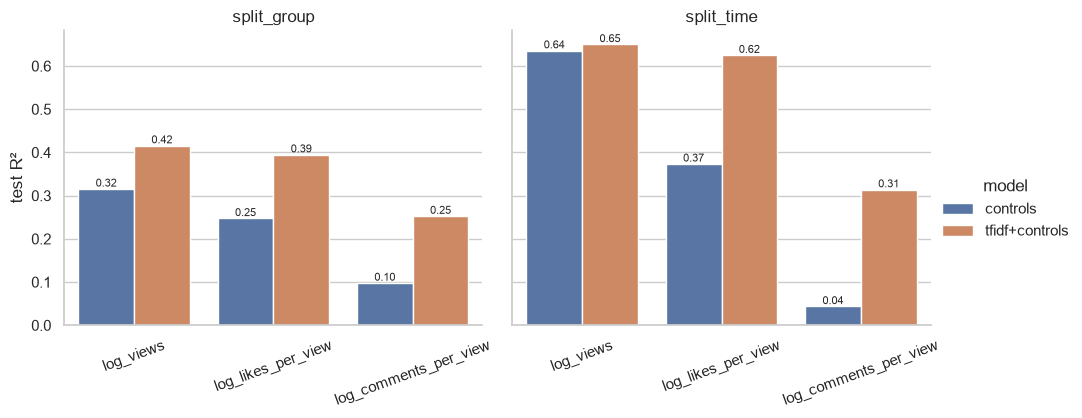

In [2]:
g = sns.catplot(
    data=metrics,
    x="target",
    y="r2",
    hue="model",
    col="split",
    kind="bar",
    height=4,
    aspect=1.2,
)
g.set_titles("{col_name}")
g.set_axis_labels("", "test R²")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=20)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.show()

## Gain in R² and RMSE from adding TF-IDF

In [3]:
gain = metrics[metrics["model"] == "tfidf+controls"][
    ["target", "split", "alpha", "n_train", "n_test", "rmse", "r2", "r2_gain_vs_controls"]
]
gain.style.format({"rmse": "{:.3f}", "r2": "{:.3f}", "r2_gain_vs_controls": "{:+.3f}"})

,target,split,alpha,n_train,n_test,rmse,r2,r2_gain_vs_controls
1,log_views,split_group,10.000000,63437,14743,0.981,0.416,+0.100
3,log_likes_per_view,split_group,1.000000,63022,14681,0.672,0.395,+0.147
5,log_comments_per_view,split_group,10.000000,62199,14576,0.939,0.252,+0.155
7,log_views,split_time,1.000000,42204,11487,0.687,0.650,+0.014
9,log_likes_per_view,split_time,1.000000,41987,11434,0.520,0.625,+0.252
11,log_comments_per_view,split_time,1.000000,41316,11363,0.801,0.314,+0.270


## Top terms
Positive = goes with a higher target, controls held fixed. Correlation, not causation.
Many terms are topics or formats (`epl`, `mv`, `trailer`), not clickbait tactics: TF-IDF
partly picks up category and channel style. Compare `split_group` with `split_time`: terms
that appear in both are more robust.

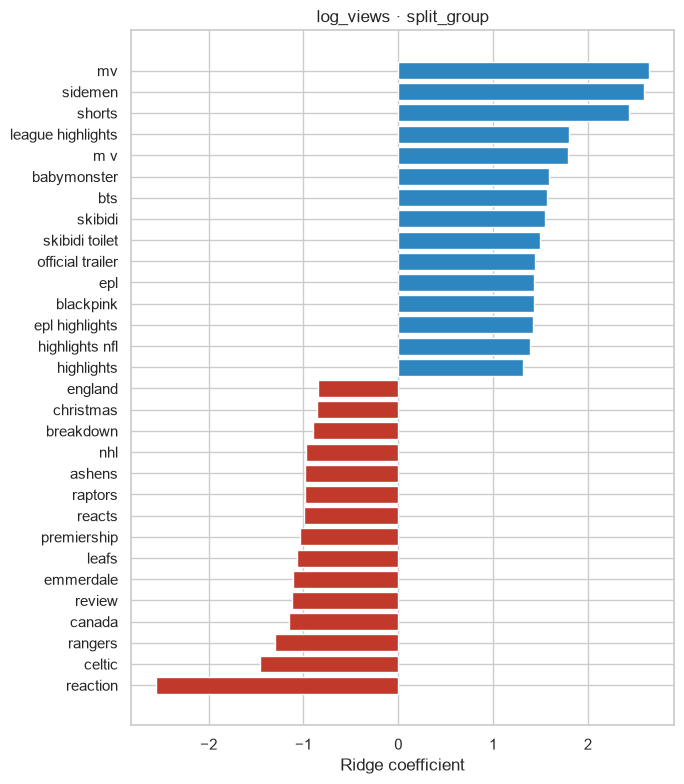

In [4]:
def plot_terms(target, split, n=15):
    d = terms[(terms["target"] == target) & (terms["split"] == split)]
    d = pd.concat([d[d.direction == "positive"].head(n), d[d.direction == "negative"].head(n)])
    d = d.sort_values("coef")
    colors = ["#c0392b" if c < 0 else "#2e86c1" for c in d["coef"]]
    fig, ax = plt.subplots(figsize=(7, 8))
    ax.barh(d["term"], d["coef"], color=colors)
    ax.set_title(f"{target} · {split}")
    ax.set_xlabel("Ridge coefficient")
    plt.tight_layout()
    plt.show()


plot_terms("log_views", "split_group")

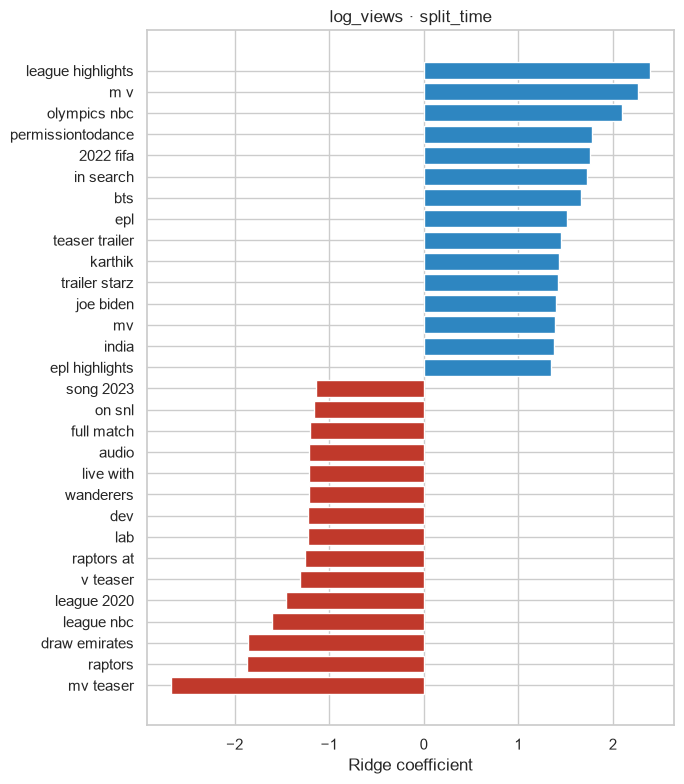

In [5]:
plot_terms("log_views", "split_time")

Change the target (`log_likes_per_view`, `log_comments_per_view`) to see engagement.

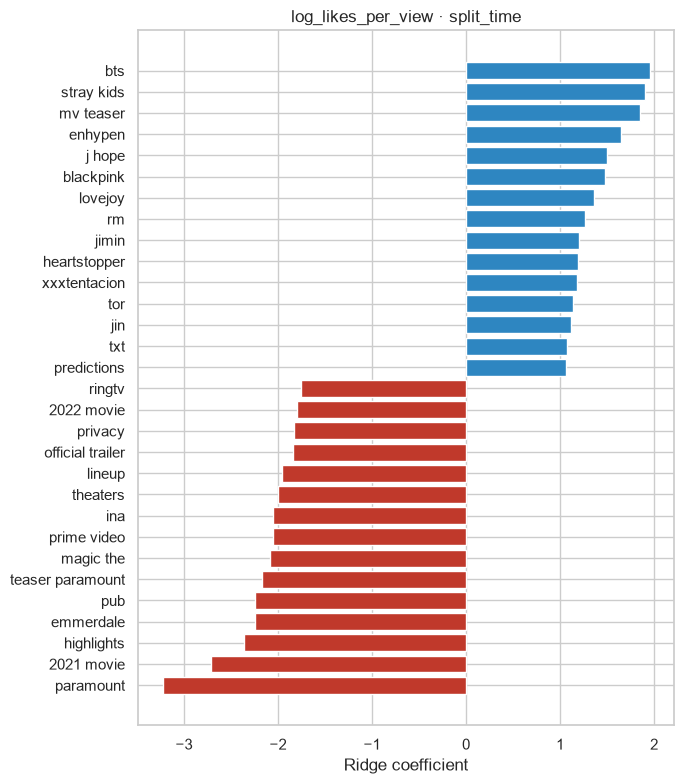

In [6]:
plot_terms("log_likes_per_view", "split_time")

## Terms that agree across both splits (log_views)

In [7]:
def term_sets(target, direction, n=30):
    out = {}
    for s in ["split_group", "split_time"]:
        d = terms[(terms.target == target) & (terms.split == s) & (terms.direction == direction)]
        out[s] = set(d.head(n).term)
    return out


for direction in ["positive", "negative"]:
    s = term_sets("log_views", direction)
    print(direction, "in both:", sorted(s["split_group"] & s["split_time"]))

positive in both: ['2022 fifa', 'bts', 'epl', 'epl highlights', 'india', 'league highlights', 'm v', 'mv']
negative in both: ['audio', 'mv teaser', 'raptors']


## Takeaways
- Controls already explain most of the variation; the title adds little within a creator
  (`split_time`, `log_views`).
- Big gains on engagement and `split_group` mostly reflect topic and format, not clickbait
  tactics.
- For the clickbait question, use the rule-feature models; use these terms as context.